In [1]:
# Text classification does not need torchvision; mismatched torchvision builds can break transformers imports.
%pip uninstall -y torchvision torchaudio torchtext
%pip install -q -U "transformers>=4.48,<5" accelerate scikit-learn pandas seaborn matplotlib nltk


Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 7.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 70.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 87.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 61.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.6 MB/s eta 0:00:00
E

In [2]:
# --- Shared setup: ELECTRA + RoBERTa hybrid experiments ---
import copy
import os
import random
import re
import time
from pathlib import Path

import nltk
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords, wordnet
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModel, AutoTokenizer

os.environ["WANDB_DISABLED"] = "true"
os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["TRANSFORMERS_NO_FLAX"] = "1"

SPLIT_SEED = 42
TRAIN_SEEDS = [42, 123, 2024]
RANDOM_STATE = SPLIT_SEED
ELECTRA_MODEL_NAME = "google/electra-base-discriminator"
ROBERTA_MODEL_NAME = "roberta-base"
DATA_URL = "https://raw.githubusercontent.com/egbertbritannia-cpu/rbl-requirements-classification/main/data/exp/promise_exp.csv"
LOCAL_DATA_PATHS = [
    Path("data/exp/promise_exp.csv"),
    Path("../data/exp/promise_exp.csv"),
]

MAX_LENGTH = 128
NUM_EPOCHS = 30
LEARNING_RATE = 2e-5
TRAIN_BATCH_SIZE = 4
EVAL_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 4
EARLY_STOPPING_PATIENCE = None  # Disabled so SERF experiments always run all 30 epochs.
USE_GRADIENT_CHECKPOINTING = True

AUGMENTATION_TARGETS = {
    "FT": 200,
    "L": 200,
    "MN": 200,
    "A": 200,
    "LF": 200,
    "SC": 200,
    "PO": 200,
    "PE": 200,
    "O": 200,
    "US": 200,
    "SE": 100,
}
KEEP_WORDS = {"not", "no", "shall", "must", "should", "will", "cannot", "never", "only"}

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_all_seeds(SPLIT_SEED)

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
stop_words = set(stopwords.words("english")) - KEEP_WORDS


def normalize_requirement_text(text):
    return re.sub(r"\s+", " ", str(text)).strip()


def get_synonyms(word):
    clean_word = re.sub(r"[^a-zA-Z]", "", str(word).lower())
    if not clean_word:
        return []
    synonyms = set()
    for syn in wordnet.synsets(clean_word):
        for lemma in syn.lemmas():
            synonym = lemma.name().replace("_", " ").lower()
            if synonym != clean_word:
                synonyms.add(synonym)
    return list(synonyms)


def synonym_replacement(text, n=1):
    words = str(text).split()
    new_words = words.copy()
    candidates = list({
        word for word in words
        if re.sub(r"[^a-zA-Z]", "", word).lower() not in stop_words and len(word) > 3
    })
    random.shuffle(candidates)

    replaced = 0
    for word in candidates:
        synonyms = get_synonyms(word)
        if synonyms:
            synonym = random.choice(synonyms)
            new_words = [synonym if current == word else current for current in new_words]
            replaced += 1
        if replaced >= n:
            break
    return " ".join(new_words)


def phrase_insertion(text, n=1):
    phrases = ["the system shall", "must be able to", "should ensure that"]
    words = str(text).split()
    if not words:
        return str(text)
    for _ in range(n):
        words.insert(random.randint(0, len(words) - 1), random.choice(phrases))
    return " ".join(words)


def random_swap(text, n=1):
    words = str(text).split()
    if len(words) < 2:
        return str(text)
    for _ in range(n):
        i, j = random.sample(range(len(words)), 2)
        words[i], words[j] = words[j], words[i]
    return " ".join(words)


def random_deletion(text, p=0.1):
    words = str(text).split()
    if len(words) <= 1:
        return str(text)
    remaining = [word for word in words if random.random() > p]
    return " ".join(remaining) if remaining else random.choice(words)


def augment_requirement_text(text):
    text = synonym_replacement(text, n=1)
    text = phrase_insertion(text, n=1)
    text = random_swap(text, n=1)
    text = random_deletion(text, p=0.1)
    return normalize_requirement_text(text)


def load_promise_exp():
    for path in LOCAL_DATA_PATHS:
        if path.exists():
            print(f"Loaded PROMISE expanded dataset from local path: {path}")
            return pd.read_csv(path)
    print(f"Loaded PROMISE expanded dataset from URL: {DATA_URL}")
    return pd.read_csv(DATA_URL)


df = load_promise_exp()
df = df[["RequirementText", "class"]].dropna().reset_index(drop=True)
df["RequirementText"] = df["RequirementText"].astype(str).map(normalize_requirement_text)
df["class"] = df["class"].astype(str).str.strip().str.upper()
df = df[df["RequirementText"] != ""].reset_index(drop=True)
df = df[df["class"].map(df["class"].value_counts()) > 1].reset_index(drop=True)
df["model_text"] = df["RequirementText"]

label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["class"])
id2label = {idx: label for idx, label in enumerate(label_encoder.classes_)}
label2id = {label: idx for idx, label in id2label.items()}
num_labels = len(label_encoder.classes_)

train_df, val_test_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df["label"],
    random_state=SPLIT_SEED,
)
val_df, test_df = train_test_split(
    val_test_df,
    test_size=0.5,
    stratify=val_test_df["label"],
    random_state=SPLIT_SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Full distribution:", dict(df["class"].value_counts()))
print("Train distribution:", dict(train_df["class"].value_counts()))
print("Validation distribution:", dict(val_df["class"].value_counts()))
print("Test distribution:", dict(test_df["class"].value_counts()))
print("Labels:", list(label_encoder.classes_))
print("Using raw requirement text; no stopword/punctuation/digit removal.")


Loaded PROMISE expanded dataset from URL: https://raw.githubusercontent.com/egbertbritannia-cpu/rbl-requirements-classification/main/data/exp/promise_exp.csv
Full distribution: {'F': np.int64(444), 'SE': np.int64(125), 'US': np.int64(85), 'O': np.int64(77), 'PE': np.int64(67), 'LF': np.int64(49), 'A': np.int64(31), 'MN': np.int64(24), 'SC': np.int64(22), 'FT': np.int64(18), 'L': np.int64(15), 'PO': np.int64(12)}
Train distribution: {'F': np.int64(311), 'SE': np.int64(87), 'US': np.int64(59), 'O': np.int64(54), 'PE': np.int64(47), 'LF': np.int64(34), 'A': np.int64(22), 'MN': np.int64(17), 'SC': np.int64(15), 'FT': np.int64(13), 'L': np.int64(11), 'PO': np.int64(8)}
Validation distribution: {'F': np.int64(66), 'SE': np.int64(19), 'US': np.int64(13), 'O': np.int64(11), 'PE': np.int64(10), 'LF': np.int64(7), 'MN': np.int64(4), 'A': np.int64(4), 'SC': np.int64(4), 'FT': np.int64(3), 'PO': np.int64(2), 'L': np.int64(2)}
Test distribution: {'F': np.int64(67), 'SE': np.int64(19), 'US': np.int6

In [3]:
# --- Dataset, metrics, and PyTorch training loop ---
electra_tokenizer = AutoTokenizer.from_pretrained(ELECTRA_MODEL_NAME, use_fast=True)
roberta_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_MODEL_NAME, use_fast=True)


class ElectraRobertaDataset(Dataset):
    def __init__(self, frame):
        texts = frame["model_text"].astype(str).tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.electra = electra_tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_token_type_ids=True,
        )
        self.roberta = roberta_tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            "electra_input_ids": torch.tensor(self.electra["input_ids"][idx], dtype=torch.long),
            "electra_attention_mask": torch.tensor(self.electra["attention_mask"][idx], dtype=torch.long),
            "roberta_input_ids": torch.tensor(self.roberta["input_ids"][idx], dtype=torch.long),
            "roberta_attention_mask": torch.tensor(self.roberta["attention_mask"][idx], dtype=torch.long),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }
        if "token_type_ids" in self.electra:
            item["electra_token_type_ids"] = torch.tensor(self.electra["token_type_ids"][idx], dtype=torch.long)
        return item


def make_loaders(train_frame, seed=None):
    train_ds = ElectraRobertaDataset(train_frame)
    val_ds = ElectraRobertaDataset(val_df)
    test_ds = ElectraRobertaDataset(test_df)
    generator = None
    if seed is not None:
        generator = torch.Generator()
        generator.manual_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True, generator=generator)
    val_loader = DataLoader(val_ds, batch_size=EVAL_BATCH_SIZE)
    test_loader = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE)
    return train_loader, val_loader, test_loader


def compute_class_weights(frame):
    counts = frame["label"].value_counts().sort_index()
    weights = len(frame) / (len(counts) * counts)
    return torch.tensor(weights.values, dtype=torch.float)


def compute_metrics_from_arrays(labels, preds):
    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        labels, preds, average="weighted", zero_division=0
    )
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": weighted_p,
        "recall": weighted_r,
        "f1": weighted_f1,
        "precision_macro": macro_p,
        "recall_macro": macro_r,
        "macro_F1": macro_f1,
    }


@torch.no_grad()
def evaluate_model(model, data_loader, device):
    model.eval()
    all_labels = []
    all_preds = []
    total_loss = 0.0

    for batch in data_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        outputs = model(**batch)
        total_loss += outputs["loss"].item()
        preds = outputs["logits"].argmax(dim=-1)
        all_labels.extend(batch["labels"].detach().cpu().numpy())
        all_preds.extend(preds.detach().cpu().numpy())

    labels = np.array(all_labels)
    preds = np.array(all_preds)
    metrics = compute_metrics_from_arrays(labels, preds)
    metrics["loss"] = total_loss / max(1, len(data_loader))
    return metrics, labels, preds


def train_model(model, train_loader, val_loader, run_name):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

    best_state = None
    best_macro_F1 = -1.0

    # Run all epochs for a fixed experimental protocol; keep the best validation checkpoint.
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        optimizer.zero_grad(set_to_none=True)

        for step, batch in enumerate(train_loader, start=1):
            batch = {key: value.to(device) for key, value in batch.items()}
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                outputs = model(**batch)
                loss = outputs["loss"] / GRAD_ACCUM_STEPS

            scaler.scale(loss).backward()
            total_loss += loss.item() * GRAD_ACCUM_STEPS

            if step % GRAD_ACCUM_STEPS == 0 or step == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)

        val_metrics, _, _ = evaluate_model(model, val_loader, device)
        train_loss = total_loss / max(1, len(train_loader))
        print(
            f"{run_name} | Epoch {epoch:02d} | train_loss={train_loss:.4f} "
            f"| val_loss={val_metrics['loss']:.4f} | val_macro_F1={val_metrics['macro_F1']:.4f}"
        )

        if val_metrics["macro_F1"] > best_macro_F1:
            best_macro_F1 = val_metrics["macro_F1"]
            best_state = copy.deepcopy(model.state_dict())

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, device


def evaluate_and_plot(model, device, test_loader, run_name):
    metrics, labels, preds = evaluate_model(model, test_loader, device)
    print(f"{run_name} test metrics:", metrics)
    print(classification_report(
        labels,
        preds,
        target_names=label_encoder.classes_,
        zero_division=0,
    ))

    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        cmap="Blues",
    )
    plt.title(f"Confusion Matrix - {run_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    return metrics


def summarize_seed_results(results_df, metric_columns):
    summary = results_df[metric_columns].agg(["mean", "std"]).T
    summary["mean ± std"] = summary.apply(
        lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}",
        axis=1,
    )
    return summary


def run_fusion_experiments(train_frame, experiment_name, run_seed=None, run_gated=True):
    if run_seed is None:
        run_seed = RANDOM_STATE
    set_all_seeds(run_seed)
    train_loader, val_loader, test_loader = make_loaders(train_frame, seed=run_seed)
    class_weights = compute_class_weights(train_frame)
    results = []

    start_time = time.perf_counter()
    naive_model = ElectraRobertaNaiveFusion(num_labels=num_labels, class_weights=class_weights)
    naive_model = enable_memory_saving(naive_model)
    naive_model, naive_device = train_model(
        naive_model,
        train_loader,
        val_loader,
        run_name=f"ELECTRA+RoBERTa Naive Fusion ({experiment_name}, seed={run_seed})",
    )
    naive_metrics = evaluate_and_plot(
        naive_model,
        naive_device,
        test_loader,
        run_name=f"ELECTRA+RoBERTa Naive Fusion ({experiment_name}, seed={run_seed})",
    )
    naive_metrics["runtime_seconds"] = time.perf_counter() - start_time
    naive_metrics["seed"] = run_seed
    results.append({"model": f"ELECTRA+RoBERTa Naive Fusion ({experiment_name})", **naive_metrics})
    print(f"ELECTRA+RoBERTa Naive Fusion ({experiment_name}) | seed={run_seed} | runtime_seconds={naive_metrics['runtime_seconds']:.2f}")

    if run_gated:
        start_time = time.perf_counter()
        gated_model = ElectraRobertaGatedFusion(num_labels=num_labels, class_weights=class_weights)
        gated_model = enable_memory_saving(gated_model)
        gated_model, gated_device = train_model(
            gated_model,
            train_loader,
            val_loader,
            run_name=f"ELECTRA+RoBERTa Gated Fusion ({experiment_name}, seed={run_seed})",
        )
        gated_metrics = evaluate_and_plot(
            gated_model,
            gated_device,
            test_loader,
            run_name=f"ELECTRA+RoBERTa Gated Fusion ({experiment_name}, seed={run_seed})",
        )
        gated_metrics["runtime_seconds"] = time.perf_counter() - start_time
        gated_metrics["seed"] = run_seed
        results.append({"model": f"ELECTRA+RoBERTa Gated Fusion ({experiment_name})", **gated_metrics})
        print(f"ELECTRA+RoBERTa Gated Fusion ({experiment_name}) | seed={run_seed} | runtime_seconds={gated_metrics['runtime_seconds']:.2f}")

    return results


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [4]:
# --- ELECTRA + RoBERTa fusion models ---
def cls_pool(outputs):
    return outputs.last_hidden_state[:, 0, :]


def enable_memory_saving(model):
    if USE_GRADIENT_CHECKPOINTING:
        for encoder in [model.electra_encoder, model.roberta_encoder]:
            if hasattr(encoder, "gradient_checkpointing_enable"):
                encoder.gradient_checkpointing_enable()
    return model


def freeze_lower_encoder_layers(encoder):
    # Freeze lower transformer layers to reduce overfitting on short requirement texts.
    for layer in encoder.encoder.layer[:8]:
        for param in layer.parameters():
            param.requires_grad = False


def report_trainable_and_frozen_parameters(model, model_name):
    trainable_params = sum(param.numel() for param in model.parameters() if param.requires_grad)
    frozen_params = sum(param.numel() for param in model.parameters() if not param.requires_grad)
    print(f"{model_name} trainable parameters: {trainable_params:,}")
    print(f"{model_name} frozen parameters: {frozen_params:,}")


class ElectraRobertaNaiveFusion(nn.Module):
    def __init__(self, num_labels, class_weights=None):
        super().__init__()
        self.electra_encoder = AutoModel.from_pretrained(ELECTRA_MODEL_NAME)
        self.roberta_encoder = AutoModel.from_pretrained(ROBERTA_MODEL_NAME)
        freeze_lower_encoder_layers(self.electra_encoder)
        freeze_lower_encoder_layers(self.roberta_encoder)
        electra_hidden = self.electra_encoder.config.hidden_size
        roberta_hidden = self.roberta_encoder.config.hidden_size
        fusion_size = electra_hidden + roberta_hidden
        self.dropout = nn.Dropout(0.2)
        self.fusion = nn.Sequential(
            nn.LayerNorm(fusion_size),
            nn.Linear(fusion_size, 768),
            nn.GELU(),
            nn.Dropout(0.2),
        )
        self.classifier = nn.Linear(768, num_labels)
        self.register_buffer("class_weights", class_weights if class_weights is not None else torch.ones(num_labels))
        report_trainable_and_frozen_parameters(self, "ElectraRobertaNaiveFusion")

    def forward(
        self,
        electra_input_ids,
        electra_attention_mask,
        roberta_input_ids,
        roberta_attention_mask,
        labels=None,
        electra_token_type_ids=None,
    ):
        electra_kwargs = {"input_ids": electra_input_ids, "attention_mask": electra_attention_mask}
        if electra_token_type_ids is not None:
            electra_kwargs["token_type_ids"] = electra_token_type_ids

        h_electra = cls_pool(self.electra_encoder(**electra_kwargs))
        h_roberta = cls_pool(self.roberta_encoder(
            input_ids=roberta_input_ids,
            attention_mask=roberta_attention_mask,
        ))
        h = torch.cat([h_electra, h_roberta], dim=-1)
        logits = self.classifier(self.fusion(self.dropout(h)))

        loss = None
        if labels is not None:
            loss = nn.functional.cross_entropy(logits, labels, weight=self.class_weights)
        return {"loss": loss, "logits": logits}


class ElectraRobertaGatedFusion(nn.Module):
    def __init__(self, num_labels, class_weights=None):
        super().__init__()
        self.electra_encoder = AutoModel.from_pretrained(ELECTRA_MODEL_NAME)
        self.roberta_encoder = AutoModel.from_pretrained(ROBERTA_MODEL_NAME)
        freeze_lower_encoder_layers(self.electra_encoder)
        freeze_lower_encoder_layers(self.roberta_encoder)
        electra_hidden = self.electra_encoder.config.hidden_size
        roberta_hidden = self.roberta_encoder.config.hidden_size
        shared_hidden = 768
        self.electra_projection = nn.Linear(electra_hidden, shared_hidden)
        self.roberta_projection = nn.Linear(roberta_hidden, shared_hidden)
        self.gate = nn.Sequential(
            nn.LayerNorm(shared_hidden * 2),
            nn.Linear(shared_hidden * 2, shared_hidden),
            nn.Sigmoid(),
        )
        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Sequential(
            nn.LayerNorm(shared_hidden),
            nn.Linear(shared_hidden, shared_hidden),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(shared_hidden, num_labels),
        )
        self.register_buffer("class_weights", class_weights if class_weights is not None else torch.ones(num_labels))
        report_trainable_and_frozen_parameters(self, "ElectraRobertaGatedFusion")

    def forward(
        self,
        electra_input_ids,
        electra_attention_mask,
        roberta_input_ids,
        roberta_attention_mask,
        labels=None,
        electra_token_type_ids=None,
    ):
        electra_kwargs = {"input_ids": electra_input_ids, "attention_mask": electra_attention_mask}
        if electra_token_type_ids is not None:
            electra_kwargs["token_type_ids"] = electra_token_type_ids

        h_electra = cls_pool(self.electra_encoder(**electra_kwargs))
        h_roberta = cls_pool(self.roberta_encoder(
            input_ids=roberta_input_ids,
            attention_mask=roberta_attention_mask,
        ))
        h_electra = self.electra_projection(h_electra)
        h_roberta = self.roberta_projection(h_roberta)
        h_concat = torch.cat([h_electra, h_roberta], dim=-1)
        gate = self.gate(h_concat)
        h_fused = gate * h_electra + (1.0 - gate) * h_roberta
        logits = self.classifier(self.dropout(h_fused))

        loss = None
        if labels is not None:
            loss = nn.functional.cross_entropy(logits, labels, weight=self.class_weights)
        return {"loss": loss, "logits": logits}


In [5]:
# --- SERF / CA-ERF selective routing helpers ---
RISKY_CLASSES = {"A", "L", "FT", "MN", "PO", "SC", "PE", "O", "US"}
RISKY_LABEL_IDS = {label2id[label] for label in RISKY_CLASSES if label in label2id}
TAU_VALUES = [0.70, 0.80, 0.85, 0.90]
DELTA_VALUES = [0.15, 0.20]

SERF_METRIC_COLUMNS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "precision_macro",
    "recall_macro",
    "macro_F1",
    "loss",
    "route_to_fusion_rate",
    "electra_only_rate",
    "mean_confidence",
    "mean_margin",
    "mean_entropy",
    "electra_train_seconds",
    "fusion_train_seconds",
    "threshold_search_seconds",
    "routed_test_seconds",
    "runtime_seconds",
]


class ElectraOnlyClassifier(nn.Module):
    def __init__(self, num_labels, class_weights=None):
        super().__init__()
        self.electra_encoder = AutoModel.from_pretrained(ELECTRA_MODEL_NAME)
        freeze_lower_encoder_layers(self.electra_encoder)
        electra_hidden = self.electra_encoder.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(electra_hidden),
            nn.Linear(electra_hidden, electra_hidden),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(electra_hidden, num_labels),
        )
        self.register_buffer("class_weights", class_weights if class_weights is not None else torch.ones(num_labels))
        report_trainable_and_frozen_parameters(self, "ElectraOnlyClassifier")

    def forward(
        self,
        electra_input_ids,
        electra_attention_mask,
        labels=None,
        electra_token_type_ids=None,
        **kwargs,
    ):
        electra_kwargs = {"input_ids": electra_input_ids, "attention_mask": electra_attention_mask}
        if electra_token_type_ids is not None:
            electra_kwargs["token_type_ids"] = electra_token_type_ids

        h_electra = cls_pool(self.electra_encoder(**electra_kwargs))
        logits = self.classifier(h_electra)

        loss = None
        if labels is not None:
            loss = nn.functional.cross_entropy(logits, labels, weight=self.class_weights)
        return {"loss": loss, "logits": logits}


def enable_electra_memory_saving(model):
    if USE_GRADIENT_CHECKPOINTING and hasattr(model.electra_encoder, "gradient_checkpointing_enable"):
        model.electra_encoder.gradient_checkpointing_enable()
    return model


def predicted_risky_mask(preds, risky_label_ids):
    risky_mask = torch.zeros_like(preds, dtype=torch.bool)
    for risky_id in risky_label_ids:
        risky_mask |= preds.eq(int(risky_id))
    return risky_mask


@torch.no_grad()
def evaluate_selective_routing(electra_model, fusion_model, data_loader, device, tau, delta, risky_label_ids):
    electra_model.eval()
    fusion_model.eval()

    all_labels = []
    all_preds = []
    all_route_to_fusion = []
    all_confidence = []
    all_margin = []
    all_entropy = []
    total_loss = 0.0

    for batch in data_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        labels = batch["labels"]

        electra_outputs = electra_model(**batch)
        electra_logits = electra_outputs["logits"]
        electra_probs = torch.softmax(electra_logits, dim=-1)
        top2 = torch.topk(electra_probs, k=2, dim=-1).values
        confidence = top2[:, 0]
        margin = top2[:, 0] - top2[:, 1]
        entropy = -(electra_probs * torch.log(electra_probs.clamp_min(1e-12))).sum(dim=-1)
        electra_preds = electra_probs.argmax(dim=-1)

        easy_mask = (
            (confidence >= tau)
            & (margin >= delta)
            & (~predicted_risky_mask(electra_preds, risky_label_ids))
        )
        route_to_fusion = ~easy_mask

        final_logits = electra_logits.clone()
        final_preds = electra_preds.clone()
        if route_to_fusion.any():
            hard_batch = {key: value[route_to_fusion] for key, value in batch.items()}
            fusion_outputs = fusion_model(**hard_batch)
            fusion_logits = fusion_outputs["logits"]
            final_logits[route_to_fusion] = fusion_logits
            final_preds[route_to_fusion] = fusion_logits.argmax(dim=-1)

        total_loss += nn.functional.cross_entropy(
            final_logits,
            labels,
            weight=electra_model.class_weights,
        ).item()
        all_labels.extend(labels.detach().cpu().numpy())
        all_preds.extend(final_preds.detach().cpu().numpy())
        all_route_to_fusion.extend(route_to_fusion.detach().cpu().numpy())
        all_confidence.extend(confidence.detach().cpu().numpy())
        all_margin.extend(margin.detach().cpu().numpy())
        all_entropy.extend(entropy.detach().cpu().numpy())

    labels = np.array(all_labels)
    preds = np.array(all_preds)
    route_to_fusion = np.array(all_route_to_fusion, dtype=bool)
    metrics = compute_metrics_from_arrays(labels, preds)
    metrics["loss"] = total_loss / max(1, len(data_loader))
    metrics["route_to_fusion_rate"] = float(route_to_fusion.mean())
    metrics["electra_only_rate"] = float((~route_to_fusion).mean())
    metrics["mean_confidence"] = float(np.mean(all_confidence))
    metrics["mean_margin"] = float(np.mean(all_margin))
    metrics["mean_entropy"] = float(np.mean(all_entropy))
    metrics["tau"] = tau
    metrics["delta"] = delta
    return metrics, labels, preds


def tune_serf_thresholds(electra_model, fusion_model, val_loader, device):
    rows = []
    for tau in TAU_VALUES:
        for delta in DELTA_VALUES:
            metrics, _, _ = evaluate_selective_routing(
                electra_model,
                fusion_model,
                val_loader,
                device,
                tau=tau,
                delta=delta,
                risky_label_ids=RISKY_LABEL_IDS,
            )
            rows.append(metrics)

    threshold_df = pd.DataFrame(rows)
    best_row = threshold_df.sort_values(
        ["macro_F1", "route_to_fusion_rate", "accuracy"],
        ascending=[False, True, False],
    ).iloc[0].to_dict()
    return threshold_df, best_row


def plot_serf_confusion_matrix(labels, preds, run_name):
    print(classification_report(
        labels,
        preds,
        target_names=label_encoder.classes_,
        zero_division=0,
    ))
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        cmap="Blues",
    )
    plt.title(f"Confusion Matrix - {run_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


def run_serf_experiment(train_frame, experiment_name, run_seed=None):
    if run_seed is None:
        run_seed = RANDOM_STATE

    total_start = time.perf_counter()
    class_weights = compute_class_weights(train_frame)

    set_all_seeds(run_seed)
    electra_train_loader, electra_val_loader, electra_test_loader = make_loaders(train_frame, seed=run_seed)
    electra_start = time.perf_counter()
    electra_model = ElectraOnlyClassifier(num_labels=num_labels, class_weights=class_weights)
    electra_model = enable_electra_memory_saving(electra_model)
    electra_model, device = train_model(
        electra_model,
        electra_train_loader,
        electra_val_loader,
        run_name=f"ELECTRA-only selector ({experiment_name}, seed={run_seed})",
    )
    electra_train_seconds = time.perf_counter() - electra_start

    # Reset the seed and recreate loaders so Naive Fusion keeps the same seeded setup as its baseline run.
    set_all_seeds(run_seed)
    fusion_train_loader, fusion_val_loader, fusion_test_loader = make_loaders(train_frame, seed=run_seed)
    fusion_start = time.perf_counter()
    fusion_model = ElectraRobertaNaiveFusion(num_labels=num_labels, class_weights=class_weights)
    fusion_model = enable_memory_saving(fusion_model)
    fusion_model, fusion_device = train_model(
        fusion_model,
        fusion_train_loader,
        fusion_val_loader,
        run_name=f"ELECTRA+RoBERTa Naive Fusion hard branch ({experiment_name}, seed={run_seed})",
    )
    fusion_train_seconds = time.perf_counter() - fusion_start

    threshold_start = time.perf_counter()
    threshold_df, best_threshold = tune_serf_thresholds(
        electra_model,
        fusion_model,
        fusion_val_loader,
        fusion_device,
    )
    threshold_search_seconds = time.perf_counter() - threshold_start

    test_start = time.perf_counter()
    test_metrics, test_labels, test_preds = evaluate_selective_routing(
        electra_model,
        fusion_model,
        fusion_test_loader,
        fusion_device,
        tau=best_threshold["tau"],
        delta=best_threshold["delta"],
        risky_label_ids=RISKY_LABEL_IDS,
    )
    routed_test_seconds = time.perf_counter() - test_start

    run_name = f"SERF/CA-ERF ({experiment_name}, seed={run_seed})"
    print(
        f"{run_name} | selected_tau={best_threshold['tau']:.2f} "
        f"| selected_delta={best_threshold['delta']:.2f} "
        f"| val_macro_F1={best_threshold['macro_F1']:.4f} "
        f"| test_macro_F1={test_metrics['macro_F1']:.4f} "
        f"| route_to_fusion_rate={test_metrics['route_to_fusion_rate']:.4f}"
    )
    plot_serf_confusion_matrix(test_labels, test_preds, run_name)

    result = {
        "model": f"SERF/CA-ERF ({experiment_name})",
        "seed": run_seed,
        "selected_tau": best_threshold["tau"],
        "selected_delta": best_threshold["delta"],
        "val_accuracy": best_threshold["accuracy"],
        "val_macro_F1": best_threshold["macro_F1"],
        "val_route_to_fusion_rate": best_threshold["route_to_fusion_rate"],
        **test_metrics,
        "electra_train_seconds": electra_train_seconds,
        "fusion_train_seconds": fusion_train_seconds,
        "threshold_search_seconds": threshold_search_seconds,
        "routed_test_seconds": routed_test_seconds,
        "runtime_seconds": time.perf_counter() - total_start,
    }

    threshold_df = threshold_df.copy()
    threshold_df["model"] = f"SERF/CA-ERF ({experiment_name})"
    threshold_df["seed"] = run_seed
    threshold_df["selected"] = (
        (threshold_df["tau"] == best_threshold["tau"])
        & (threshold_df["delta"] == best_threshold["delta"])
    )
    return result, threshold_df


Augmented rows added: 1733
Augmented train distribution: {'F': np.int64(311), 'PE': np.int64(200), 'US': np.int64(200), 'FT': np.int64(200), 'O': np.int64(200), 'SC': np.int64(200), 'LF': np.int64(200), 'A': np.int64(200), 'PO': np.int64(200), 'MN': np.int64(200), 'L': np.int64(200), 'SE': np.int64(100)}


pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

ElectraOnlyClassifier trainable parameters: 52,790,028
ElectraOnlyClassifier frozen parameters: 56,702,976


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

/tmp/ipykernel_907/3344550988.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


...

ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=42) | Epoch 28 | train_loss=0.0019 | val_loss=2.4665 | val_macro_F1=0.6055


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=42) | Epoch 29 | train_loss=0.0190 | val_loss=2.0185 | val_macro_F1=0.6001


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=42) | Epoch 30 | train_loss=0.0024 | val_loss=2.3801 | val_macro_F1=0.6292
SERF/CA-ERF (with augmentation, seed=42) | selected_tau=0.90 | selected_delta=0.15 | val_macro_F1=0.7441 | test_macro_F1=0.6611 | route_to_fusion_rate=0.3630
              precision    recall  f1-score   support

           A       1.00      0.40      0.57         5
           F       0.85      0.99      0.91        67
          FT       0.40      1.00      0.57         2
           L       1.00      1.00      1.00         2
          LF       0.78      0.88      0.82         8
          MN       0.33      0.33      0.33         3
           O       0.78      0.58      0.67        12
          PE       0.90      0.90      0.90        10
          PO       0.00      0.00      0.00         2
          SC       1.00      0.33      0.50         3
          SE       0.89      0.89      0.89        19
          US       1.00      0.62      0.76        1

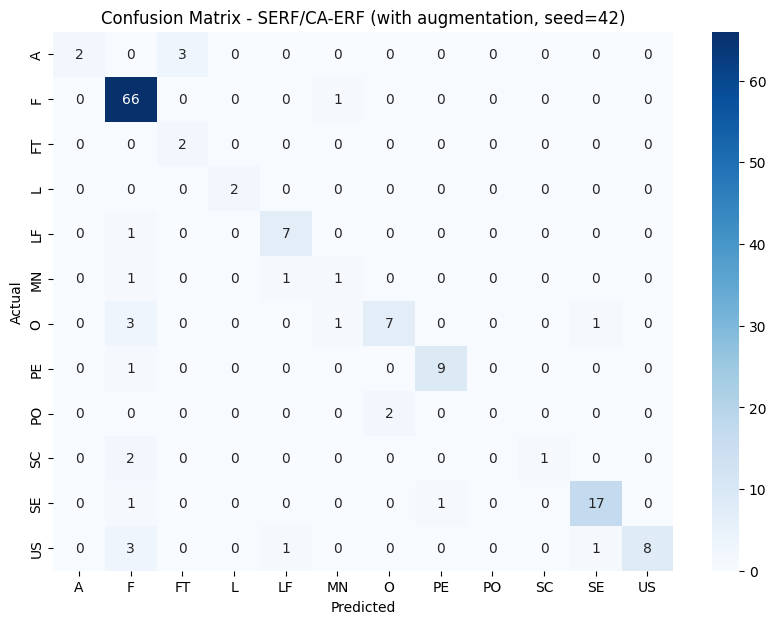

ElectraOnlyClassifier trainable parameters: 52,790,028
ElectraOnlyClassifier frozen parameters: 56,702,976


/tmp/ipykernel_907/3344550988.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA-only selector (with augmentation, seed=123) | Epoch 01 | train_loss=2.1898 | val_loss=1.4818 | val_macro_F1=0.3599


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA-only selector (with augmentation, seed=123) | Epoch 02 | train_loss=1.1520 | val_loss=0.8656 | val_macro_F1=0.5909


...

ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=123) | Epoch 28 | train_loss=0.0079 | val_loss=1.8515 | val_macro_F1=0.6531


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=123) | Epoch 29 | train_loss=0.0015 | val_loss=2.1671 | val_macro_F1=0.6487


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=123) | Epoch 30 | train_loss=0.0007 | val_loss=2.0441 | val_macro_F1=0.6488
SERF/CA-ERF (with augmentation, seed=123) | selected_tau=0.70 | selected_delta=0.15 | val_macro_F1=0.6878 | test_macro_F1=0.6828 | route_to_fusion_rate=0.3288
              precision    recall  f1-score   support

           A       1.00      0.60      0.75         5
           F       0.81      0.99      0.89        67
          FT       0.67      1.00      0.80         2
           L       1.00      1.00      1.00         2
          LF       0.86      0.75      0.80         8
          MN       0.33      0.33      0.33         3
           O       0.78      0.58      0.67        12
          PE       0.82      0.90      0.86        10
          PO       0.00      0.00      0.00         2
          SC       1.00      0.33      0.50         3
          SE       0.89      0.89      0.89        19
          US       1.00      0.54      0.70       

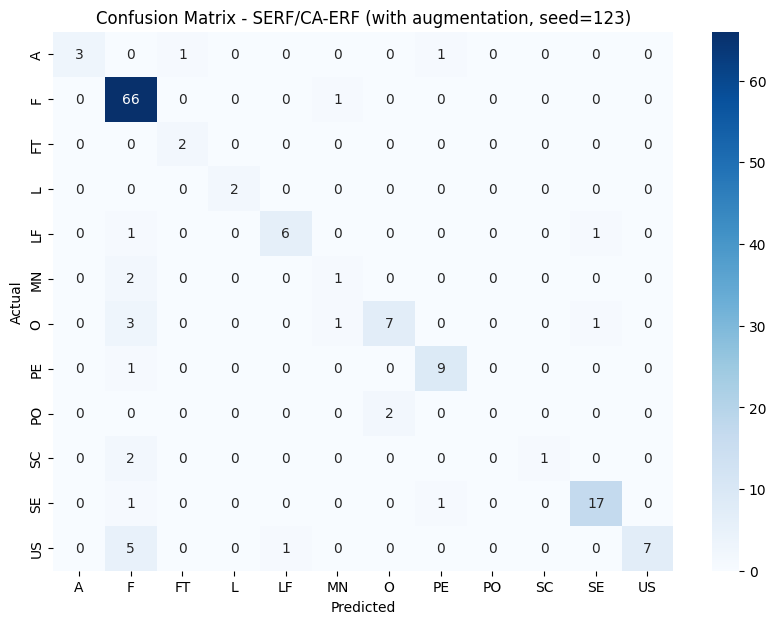

ElectraOnlyClassifier trainable parameters: 52,790,028
ElectraOnlyClassifier frozen parameters: 56,702,976


/tmp/ipykernel_907/3344550988.py:104: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA-only selector (with augmentation, seed=2024) | Epoch 01 | train_loss=2.1804 | val_loss=1.4893 | val_macro_F1=0.4131


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA-only selector (with augmentation, seed=2024) | Epoch 02 | train_loss=1.1520 | val_loss=0.8482 | val_macro_F1=0.6618


...

ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=2024) | Epoch 28 | train_loss=0.0045 | val_loss=1.4026 | val_macro_F1=0.6086


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=2024) | Epoch 29 | train_loss=0.0058 | val_loss=1.2046 | val_macro_F1=0.6320


/tmp/ipykernel_907/3344550988.py:117: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


ELECTRA+RoBERTa Naive Fusion hard branch (with augmentation, seed=2024) | Epoch 30 | train_loss=0.0019 | val_loss=1.6801 | val_macro_F1=0.6683
SERF/CA-ERF (with augmentation, seed=2024) | selected_tau=0.70 | selected_delta=0.15 | val_macro_F1=0.7193 | test_macro_F1=0.7545 | route_to_fusion_rate=0.3356
              precision    recall  f1-score   support

           A       1.00      0.40      0.57         5
           F       0.84      0.96      0.90        67
          FT       0.50      1.00      0.67         2
           L       1.00      1.00      1.00         2
          LF       0.86      0.75      0.80         8
          MN       0.67      0.67      0.67         3
           O       0.89      0.67      0.76        12
          PE       0.82      0.90      0.86        10
          PO       1.00      0.50      0.67         2
          SC       1.00      0.33      0.50         3
          SE       0.81      0.89      0.85        19
          US       1.00      0.69      0.82     

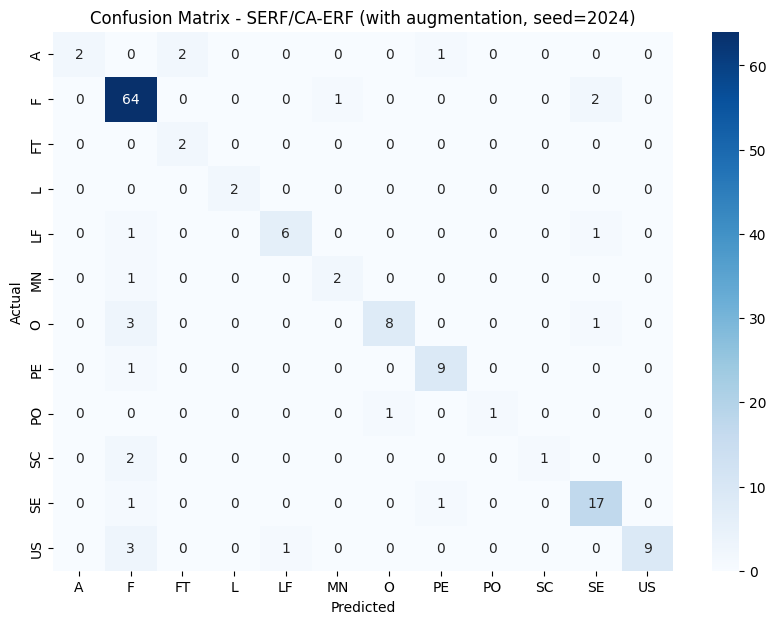

SERF/CA-ERF with augmentation validation threshold search:


,accuracy,precision,recall,f1,precision_macro,recall_macro,macro_F1,loss,route_to_fusion_rate,electra_only_rate,mean_confidence,mean_margin,mean_entropy,tau,delta,model,seed,selected
0,0.834483,0.819004,0.834483,0.820570,0.684722,0.703799,0.686933,1.266131,0.379310,0.620690,0.939971,0.896815,0.181225,0.70,0.15,SERF/CA-ERF (with augmentation),42,False
1,0.834483,0.819004,0.834483,0.820570,0.684722,0.703799,0.686933,1.266131,0.379310,0.620690,0.939971,0.896815,0.181225,0.70,0.20,SERF/CA-ERF (with augmentation),42,False
2,0.841379,0.833592,0.841379,0.832315,0.762525,0.745465,0.741463,1.275881,0.413793,0.586207,0.939971,0.896815,0.181225,0.80,0.15,SERF/CA-ERF (with augmentation),42,False
3,0.841379,0.833592,0.841379,0.832315,0.762525,0.745465,0.741463,1.275881,0.413793,0.586207,0.939971,0.896815,0.181225,0.80,0.20,SERF/CA-ERF (with augmentation),42,False
4,0.841379,0.833592,0.841379,0.832315,0.762525,0.745465,0.741463,1.275881,0.413793,0.586207,0.939971,0.896815,0.181225,0.85,0.15,SERF/CA-ERF (with augmentation),42,False
5,0.841379,0.833592,0.841379,0.832315,0.762525,0.745465,0.741463,1.275881,0.413793,0.586207,0.939971,0.896815,0.181225,0.85,0.20,SERF/CA-ERF (with augmentation),42,False
6,0.848276,0.841176,0.848276,0.839079,0.767017,0.746728,0.744127,1.264033,0.420690,0.579310,0.939971,0.896815,0.181225,0.90,0.15,SERF/CA-ERF (with augmentation),42,True
7,0.848276,0.841176,0.848276,0.839079,0.767017,0.746728,0.744127,1.264033,0.420690,0.579310,0.939971,0.896815,0.181225,0.90,0.20,SERF/CA-ERF (with augmentation),42,False
8,0.848276,0.822736,0.848276,0.830105,0.690907,0.698561,0.687846,1.295486,0.372414,0.627586,0.950458,0.918397,0.139857,0.70,0.15,SERF/CA-ERF (with augmentation),123,True
9,0.848276,0.822736,0.848276,0.830105,0.690907,0.698561,0.687846,1.295486,0.372414,0.627586,0.950458,0.918397,0.139857,0.70,0.20,SERF/CA-ERF (with augmentation),123,False


SERF/CA-ERF with augmentation seed-level test results:


,model,seed,selected_tau,selected_delta,val_accuracy,val_macro_F1,val_route_to_fusion_rate,accuracy,precision,recall,...,mean_confidence,mean_margin,mean_entropy,tau,delta,electra_train_seconds,fusion_train_seconds,threshold_search_seconds,routed_test_seconds,runtime_seconds
0,SERF/CA-ERF (with augmentation),42,0.9,0.15,0.848276,0.744127,0.420690,0.835616,0.842794,0.835616,...,0.942428,0.902262,0.170549,0.9,0.15,1222.010026,2226.044397,15.043462,1.800668,3467.217699
1,SERF/CA-ERF (with augmentation),123,0.7,0.15,0.848276,0.687846,0.372414,0.828767,0.830810,0.828767,...,0.960930,0.930802,0.119354,0.7,0.15,1213.345497,2221.482418,14.469407,1.726905,3452.727010
2,SERF/CA-ERF (with augmentation),2024,0.7,0.15,0.868966,0.719336,0.372414,0.842466,0.859641,0.842466,...,0.942235,0.904988,0.173528,0.7,0.15,1207.981410,2176.685970,14.548250,1.723660,3402.134965


SERF/CA-ERF with augmentation mean ± std:


,mean,std,mean ± std
accuracy,0.835616,0.006849,0.8356 ± 0.0068
precision,0.844415,0.014484,0.8444 ± 0.0145
recall,0.835616,0.006849,0.8356 ± 0.0068
f1,0.823198,0.011086,0.8232 ± 0.0111
precision_macro,0.790971,0.065020,0.7910 ± 0.0650
recall_macro,0.683261,0.040400,0.6833 ± 0.0404
macro_F1,0.699470,0.048860,0.6995 ± 0.0489
loss,1.169165,0.018375,1.1692 ± 0.0184
route_to_fusion_rate,0.342466,0.018122,0.3425 ± 0.0181
electra_only_rate,0.657534,0.018122,0.6575 ± 0.0181


In [6]:
# --- SERF / CA-ERF WITH Augmentation: 3 fixed training seeds ---
# Augmentation is generated from the training split only; validation and test remain untouched.
set_all_seeds(SPLIT_SEED)
augmented_rows = []
train_counts = train_df["class"].value_counts().to_dict()

for cls, target_count in AUGMENTATION_TARGETS.items():
    current_count = train_counts.get(cls, 0)
    needed = max(0, target_count - current_count)
    if needed == 0:
        continue
    class_df = train_df[train_df["class"] == cls].reset_index(drop=True)
    if class_df.empty:
        continue
    for _ in range(needed):
        row = class_df.sample(n=1, random_state=random.randint(0, 10**9)).iloc[0]
        aug_text = augment_requirement_text(row["RequirementText"])
        augmented_rows.append({
            "RequirementText": aug_text,
            "class": cls,
            "model_text": aug_text,
            "label": int(row["label"]),
        })

df_aug = pd.DataFrame(augmented_rows)
train_aug_df = pd.concat([train_df, df_aug], ignore_index=True) if len(df_aug) > 0 else train_df.copy()
train_aug_df = train_aug_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Augmented rows added:", len(df_aug))
print("Augmented train distribution:", dict(train_aug_df["class"].value_counts()))

serf_aug_results = []
serf_aug_threshold_rows = []

for run_seed in TRAIN_SEEDS:
    seed_result, seed_threshold_df = run_serf_experiment(
        train_aug_df,
        "with augmentation",
        run_seed=run_seed,
    )
    serf_aug_results.append(seed_result)
    serf_aug_threshold_rows.append(seed_threshold_df)

serf_aug_results_df = pd.DataFrame(serf_aug_results)
serf_aug_threshold_results_df = pd.concat(serf_aug_threshold_rows, ignore_index=True)
serf_aug_summary = summarize_seed_results(serf_aug_results_df, SERF_METRIC_COLUMNS)

print("SERF/CA-ERF with augmentation validation threshold search:")
display(serf_aug_threshold_results_df)
print("SERF/CA-ERF with augmentation seed-level test results:")
display(serf_aug_results_df)
print("SERF/CA-ERF with augmentation mean ± std:")
display(serf_aug_summary)
